# SatMAE final model

- Frozen SatMAE ViT-L encoder pretrained on fMoW RGB. A single linear layer learns the 10 EuroSAT classes.
- We use the group's shared 21,600 training and 5,400 test images. The head uses Adam (learning rate 0.001, batch size 256). A validation split within the training set picks the number of epochs.
- Run from this folder or the repo root with PyTorch, torchvision, rshf, scikit-learn and matplotlib installed. The [pretrained checkpoint](https://huggingface.co/MVRL/satmae-vitlarge-fmow-pretrain-800) downloads on first use if needed.

AI helped draft the code and explanations in this notebook.

## 1. Load the data and SatMAE

The image folders give us the class labels. We prepare each RGB image using the same steps the pretrained model expects.

In [1]:
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import torch
from rshf.satmae import SatMAE
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from sklearn.model_selection import train_test_split
from torch import nn
from torch.utils.data import DataLoader, Subset, TensorDataset
from torchvision.datasets import ImageFolder

SEED = 42
BATCH_SIZE = 32
CHECKPOINT = "MVRL/satmae-vitlarge-fmow-pretrain-800"

data_dir = Path("data") if Path("data/train").is_dir() else Path("../../data")
cache_dir = data_dir.resolve().parent / "individual-workflows/Owen/checkpoints"
cache_dir.mkdir(exist_ok=True)

# Use a GPU for the encoder if PyTorch can see one.
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
torch.set_num_threads(min(torch.get_num_threads(), 6))
torch.manual_seed(SEED)

encoder = SatMAE.from_pretrained(CHECKPOINT)
encoder.eval().requires_grad_(False)
encoder.to(device)

def prepare_image(image):
    # Keep pixels as 0–255 integers so the wrapper rescales them correctly.
    rgb = np.array(image.convert("RGB"), dtype=np.uint8)
    return encoder.transform(rgb, encoder.config.img_size)

train_images = ImageFolder(data_dir / "train", transform=prepare_image)
test_images = ImageFolder(data_dir / "test", transform=prepare_image)
class_names = train_images.classes

assert len(train_images) == 21_600 and len(test_images) == 5_400
assert len(class_names) == 10 and train_images.class_to_idx == test_images.class_to_idx

print(f"Encoder device: {device} | PyTorch {torch.__version__}")
print(f"{len(train_images):,} training images | {len(test_images):,} test images")
print(", ".join(class_names))

Encoder device: cpu | PyTorch 2.15.0
21,600 training images | 5,400 test images
AnnualCrop, Forest, HerbaceousVegetation, Highway, Industrial, Pasture, PermanentCrop, Residential, River, SeaLake


## 2. Check a small batch

We show SatMAE the whole image by setting the masking ratio to zero. We keep the first output vector, called the **class token**, which can draw on information from all the image patches. We only run the encoder.

In [2]:
@torch.inference_mode()
def embed_images(images):
    tokens, _, _ = encoder.forward_encoder(images.to(device), mask_ratio=0)
    return tokens[:, 0].contiguous().cpu()

sample_images, sample_labels = next(iter(DataLoader(train_images, batch_size=4)))
sample_embeddings = embed_images(sample_images)
assert sample_embeddings.shape == (len(sample_labels), encoder.config.embed_dim)
assert torch.isfinite(sample_embeddings).all()

print(f"Images: {tuple(sample_images.shape)}")
print(f"Embeddings: {tuple(sample_embeddings.shape)}")

Images: (4, 3, 224, 224)
Embeddings: (4, 1024)


## 3. Save the training embeddings

This is the slow part. We time opening the images, preparing them and running the encoder. We save the results in four chunks, so if the run stops it can pick up from the last saved chunk.

If we reuse saved embeddings, the reported extraction time comes from the original run.

In [3]:
def extract_split(images, split):
    feature_chunks, label_chunks, timings = [], [], []
    elapsed = 0.0
    boundaries = np.linspace(0, len(images), 5, dtype=int)

    for chunk, (first, last) in enumerate(zip(boundaries, boundaries[1:]), start=1):
        cache_file = cache_dir / f"satmae-vitlarge-cls-{split}-{chunk}.pt"
        samples = images.samples[first:last]
        image_names = [str(Path(name).relative_to(images.root)) for name, _ in samples]
        expected_labels = [label for _, label in samples]

        # Reuse a saved chunk if its images, labels and device match this run.
        saved = torch.load(cache_file, weights_only=True) if cache_file.exists() else None
        if (saved is None or saved["image_names"] != image_names
                or saved["labels"].tolist() != expected_labels or saved["device"] != str(device)):
            subset = Subset(images, range(first, last))
            loader = DataLoader(subset, batch_size=BATCH_SIZE, shuffle=False)
            features, labels = [], []
            start = perf_counter()
            for image_batch, label_batch in loader:
                features.append(embed_images(image_batch))
                labels.append(label_batch)

            saved = {
                "features": torch.cat(features),
                "labels": torch.cat(labels),
                "seconds": perf_counter() - start,
                "device": str(device),
                "image_names": image_names,
            }
            # Rename the file only after the save finishes.
            temporary_file = cache_file.with_suffix(".tmp")
            torch.save(saved, temporary_file)
            temporary_file.replace(cache_file)
            status = "processed"
        else:
            status = "reused"

        feature_chunks.append(saved["features"])
        label_chunks.append(saved["labels"])
        elapsed += saved["seconds"]
        timings.append((int(last), elapsed))
        print(f"{split}: {last:,}/{len(images):,} images in {elapsed / 60:.2f} min ({status})", flush=True)

    return torch.cat(feature_chunks), torch.cat(label_chunks), timings, str(device)


train_features, train_labels, train_timings, train_device = extract_split(train_images, "train")
print(f"Training feature matrix: {tuple(train_features.shape)}")

train: 5,400/21,600 images in 9.22 min (reused)
train: 10,800/21,600 images in 18.22 min (reused)
train: 16,200/21,600 images in 27.42 min (reused)
train: 21,600/21,600 images in 36.68 min (reused)
Training feature matrix: (21600, 1024)


## 4. Fit the linear classifier

- A single layer takes an embedding and gives it ten scores, one per class.
- We set aside 20% of the training embeddings for validation, keeping class proportions similar. Validation accuracy picks the number of epochs, or passes through the data.
- We then start with a fresh layer and fit it on all the training embeddings.

In [4]:
def fit_head(features, labels, epochs, validation=None):
    torch.manual_seed(SEED)
    head = nn.Linear(features.shape[1], len(class_names))
    optimizer = torch.optim.Adam(head.parameters(), lr=0.001)
    loss_function = nn.CrossEntropyLoss()
    batches = DataLoader(TensorDataset(features, labels), batch_size=256, shuffle=True)
    validation_scores = []

    for _ in range(epochs):
        for feature_batch, label_batch in batches:
            # Update the layer so it gives higher scores to the right classes.
            optimizer.zero_grad()
            loss = loss_function(head(feature_batch), label_batch)
            loss.backward()
            optimizer.step()

        if validation is not None:
            val_features, val_labels = validation
            with torch.inference_mode():
                predictions = head(val_features).argmax(dim=1)
                validation_scores.append((predictions == val_labels).float().mean().item())

    return head, validation_scores


fit_rows, val_rows = train_test_split(
    np.arange(len(train_labels)),
    test_size=0.20,
    random_state=SEED,
    stratify=train_labels.numpy(),
)

tuning_start = perf_counter()
_, validation_scores = fit_head(
    train_features[fit_rows], train_labels[fit_rows], epochs=20,
    validation=(train_features[val_rows], train_labels[val_rows]),
)
tuning_seconds = perf_counter() - tuning_start
best_epoch = int(np.argmax(validation_scores)) + 1

fit_start = perf_counter()
head, _ = fit_head(train_features, train_labels, epochs=best_epoch)
fit_seconds = perf_counter() - fit_start

print(f"Validation accuracy: {validation_scores[best_epoch - 1]:.2%} after {best_epoch} epochs")
print(f"Validation run: {tuning_seconds:.2f} s | Final head fitting: {fit_seconds:.2f} s")

# Save the fitted layer and the details needed to pair it with the encoder.
torch.save({
    "head_state_dict": head.state_dict(),
    "encoder_checkpoint": CHECKPOINT,
    "embedding_size": head.in_features,
    "class_names": class_names,
}, cache_dir / "satmae-linear-head.pt")


Validation accuracy: 94.03% after 20 epochs
Validation run: 1.77 s | Final head fitting: 2.01 s


## 5. Score the shared test set

We use the finished classifier on all 5,400 test images. The confusion matrix shows where it gets things wrong. Rows are the actual classes and columns are the predicted classes.

test: 1,350/5,400 images in 2.29 min (reused)
test: 2,700/5,400 images in 4.67 min (reused)
test: 4,050/5,400 images in 6.94 min (reused)
test: 5,400/5,400 images in 9.16 min (reused)
Test loss: 0.1605
Test accuracy: 95.48% (5,156/5,400)
                      precision    recall  f1-score   support

          AnnualCrop      0.954     0.930     0.942       600
              Forest      0.974     0.987     0.980       600
HerbaceousVegetation      0.942     0.950     0.946       600
             Highway      0.942     0.910     0.926       500
          Industrial      0.974     0.988     0.981       500
             Pasture      0.939     0.965     0.952       400
       PermanentCrop      0.931     0.922     0.927       500
         Residential      0.987     0.993     0.990       600
               River      0.900     0.922     0.911       500
             SeaLake      0.988     0.972     0.980       600

            accuracy                          0.955      5400
           macro

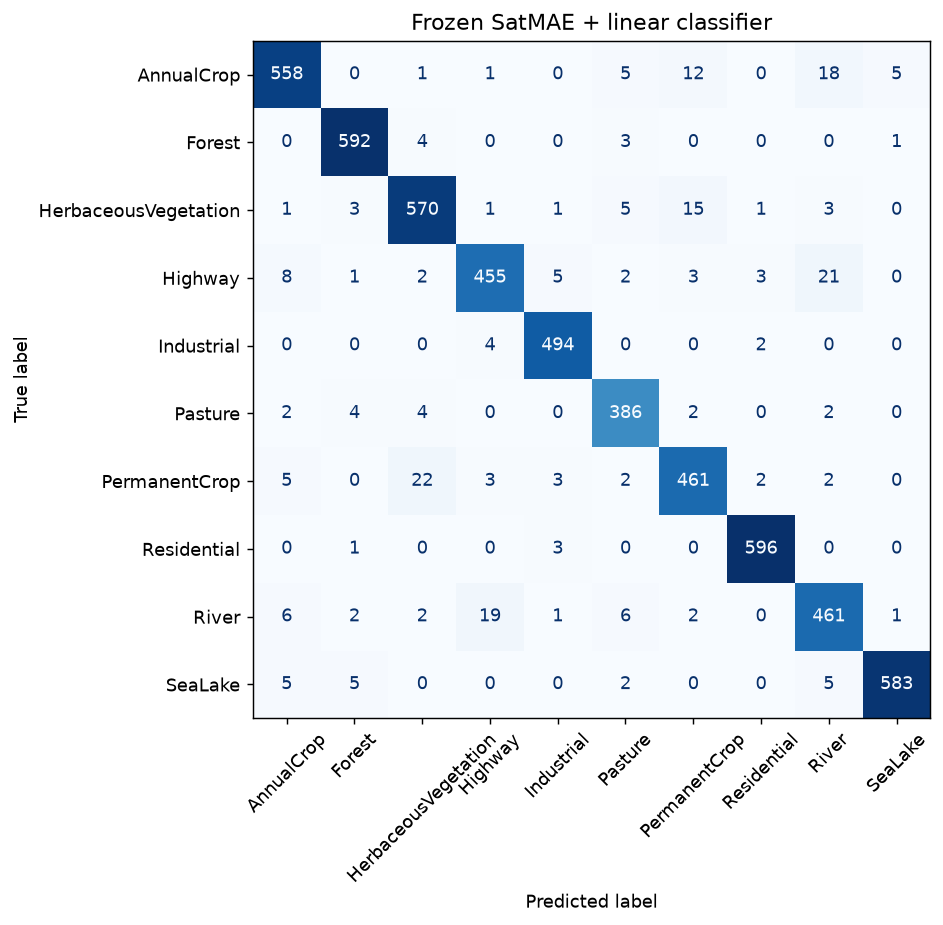

In [5]:
test_features, test_labels, test_timings, test_device = extract_split(test_images, "test")

prediction_start = perf_counter()
with torch.inference_mode():
    scores = head(test_features)
    predictions = scores.argmax(dim=1)
prediction_seconds = perf_counter() - prediction_start
correct = (predictions == test_labels).sum().item()

test_loss = nn.functional.cross_entropy(scores, test_labels).item()

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {correct / len(test_labels):.2%} ({correct:,}/{len(test_labels):,})")
print(classification_report(test_labels, predictions, target_names=class_names, digits=3))

fig, ax = plt.subplots(figsize=(9, 7), layout="constrained")
ConfusionMatrixDisplay.from_predictions(
    test_labels, predictions, display_labels=class_names, xticks_rotation=45,
    cmap="Blues", colorbar=False, ax=ax,
)
ax.set_title("Frozen SatMAE + linear classifier")
plt.show()

## 6. Runtime and scaling

- **End-to-end training** includes opening and preparing the training images, running the encoder once per image, and fitting the final classifier. Validation is timed separately.
- **End-to-end testing** includes the same image-to-embedding pass and the classifier's predictions. Cache reads and writes are outside these timings.
- At 1,000× the data, the estimate assumes the same throughput on one device. We could divide image batches across GPUs, save the embeddings in chunks, and fit the classifier by reading one batch at a time.

Trainable parameters: 10,250
Final head epochs: 20
Train feature extraction (cpu): 36.68 min
Final head fitting (CPU): 2.01 s
End-to-end training: 36.71 min
Test feature extraction (cpu): 9.16 min
Test predictions from cached features (CPU): 0.009 s
End-to-end testing: 9.16 min
Training extraction throughput: 9.82 images/s
At 1,000× (21,600,000 training images):
  Feature extraction: 611.3 hours
  Embedding storage: 88.5 GB, before labels and file overhead


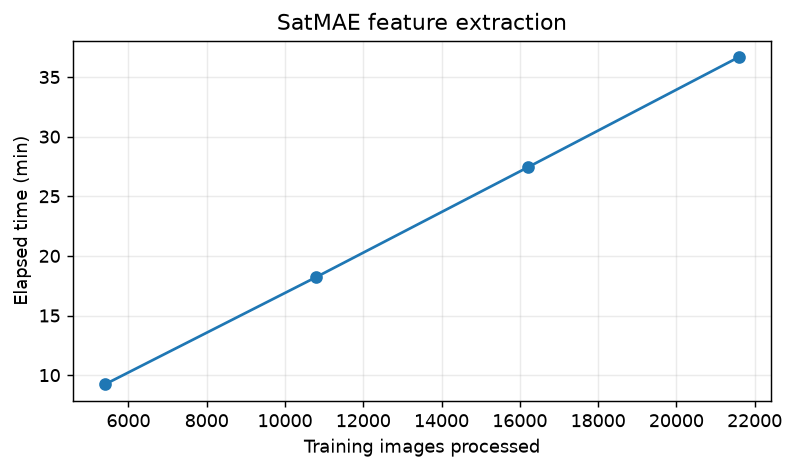

In [6]:
train_seconds = train_timings[-1][1]
test_seconds = test_timings[-1][1]
throughput = len(train_labels) / train_seconds
scaled_count = 1_000 * len(train_labels)
cache_bytes = scaled_count * train_features.shape[1] * train_features.element_size()

print(f"Trainable parameters: {sum(parameter.numel() for parameter in head.parameters()):,}")
print(f"Final head epochs: {best_epoch}")
print(f"Train feature extraction ({train_device}): {train_seconds / 60:.2f} min")
print(f"Final head fitting (CPU): {fit_seconds:.2f} s")
print(f"End-to-end training: {(train_seconds + fit_seconds) / 60:.2f} min")
print(f"Test feature extraction ({test_device}): {test_seconds / 60:.2f} min")
print(f"Test predictions from cached features (CPU): {prediction_seconds:.3f} s")
print(f"End-to-end testing: {(test_seconds + prediction_seconds) / 60:.2f} min")
print(f"Training extraction throughput: {throughput:.2f} images/s")
print(f"At 1,000× ({scaled_count:,} training images):")
print(f"  Feature extraction: {scaled_count / throughput / 3_600:,.1f} hours")
print(f"  Embedding storage: {cache_bytes / 10**9:.1f} GB, before labels and file overhead")

counts, seconds = zip(*train_timings)
fig, ax = plt.subplots(figsize=(6, 3.5), layout="constrained")
ax.plot(counts, np.array(seconds) / 60, marker="o")
ax.set(xlabel="Training images processed", ylabel="Elapsed time (min)",
       title="SatMAE feature extraction")
ax.grid(alpha=0.25)
plt.show()